<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Hands-on Lab: Interactive Visual Analytics with Folium**


Estimated time needed: **40** minutes


The launch success rate may depend on many factors such as payload mass, orbit type, and so on. It may also depend on the location and proximities of a launch site, i.e., the initial position of rocket trajectories. Finding an optimal location for building a launch site certainly involves many factors and hopefully we could discover some of the factors by analyzing the existing launch site locations.


In the previous exploratory data analysis labs, you have visualized the SpaceX launch dataset using `matplotlib` and `seaborn` and discovered some preliminary correlations between the launch site and success rates. In this lab, you will be performing more interactive visual analytics using `Folium`.


## Objectives


This lab contains the following tasks:

*   **TASK 1:** Mark all launch sites on a map
*   **TASK 2:** Mark the success/failed launches for each site on the map
*   **TASK 3:** Calculate the distances between a launch site to its proximities

After completed the above tasks, you should be able to find some geographical patterns about launch sites.


Let's first import required Python packages for this lab:


In [1]:
import piplite
await piplite.install(['folium'])
await piplite.install(['pandas'])

In [2]:
import folium
import pandas as pd

In [3]:
# Import folium MarkerCluster plugin
from folium.plugins import MarkerCluster
# Import folium MousePosition plugin
from folium.plugins import MousePosition
# Import folium DivIcon plugin
from folium.features import DivIcon

If you need to refresh your memory about folium, you may download and refer to this previous folium lab:


[Generating Maps with Python](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/v4/DV0101EN-Exercise-Generating-Maps-in-Python.ipynb)


Note: The interactive Folium maps may not be displayed on GitHub. Run the notebook in Jupyter to see and interact with the maps. The screenshots above show the results.

---

注：Folium の地図は、GitHub では表示されないことがあります。地図を表示して操作するには、Jupyter でノートブックを実行してください。上のスクリーンショットは実行結果です。

## Task 1: Mark all launch sites on a map

First, let's try to add each site's location on a map using site's latitude and longitude coordinates


The following dataset with the name `spacex_launch_geo.csv` is an augmented dataset with latitude and longitude added for each site.


In [4]:
# Download and read the `spacex_launch_geo.csv`
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv'
resp = await fetch(URL)
spacex_csv_file = io.BytesIO((await resp.arrayBuffer()).to_py())
spacex_df=pd.read_csv(spacex_csv_file)

Now, you can take a look at what are the coordinates for each site.


In [5]:
# Select relevant sub-columns: `Launch Site`, `Lat(Latitude)`, `Long(Longitude)`, `class`
spacex_df = spacex_df[['Launch Site', 'Lat', 'Long', 'class']]
launch_sites_df = spacex_df.groupby(['Launch Site'], as_index=False).first()
launch_sites_df = launch_sites_df[['Launch Site', 'Lat', 'Long']]
launch_sites_df

,Launch Site,Lat,Long
0,CCAFS LC-40,28.562302,-80.577356
1,CCAFS SLC-40,28.563197,-80.576820
2,KSC LC-39A,28.573255,-80.646895
3,VAFB SLC-4E,34.632834,-120.610745


Above coordinates are just plain numbers that can not give you any intuitive insights about where are those launch sites. If you are very good at geography, you can interpret those numbers directly in your mind. If not, that's fine too. Let's visualize those locations by pinning them on a map.


We first need to create a folium `Map` object, with an initial center location to be NASA Johnson Space Center at Houston, Texas.


In [6]:
# Start location is NASA Johnson Space Center
nasa_coordinate = [29.559684888503615, -95.0830971930759]
site_map = folium.Map(location=nasa_coordinate, zoom_start=10)

We could use `folium.Circle` to add a highlighted circle area with a text label on a specific coordinate. For example,


In [7]:
# Create a blue circle at NASA Johnson Space Center's coordinate with a popup label showing its name
circle = folium.Circle(nasa_coordinate, radius=1000, color='#d35400', fill=True).add_child(folium.Popup('NASA Johnson Space Center'))
# Create a blue circle at NASA Johnson Space Center's coordinate with a icon showing its name
marker = folium.map.Marker(
    nasa_coordinate,
    # Create an icon as a text label
    icon=DivIcon(
        icon_size=(20,20),
        icon_anchor=(0,0),
        html='<div style="font-size: 12px; color:#d35400;"><b>%s</b></div>' % 'NASA JSC',
        )
    )
site_map.add_child(circle)
site_map.add_child(marker)

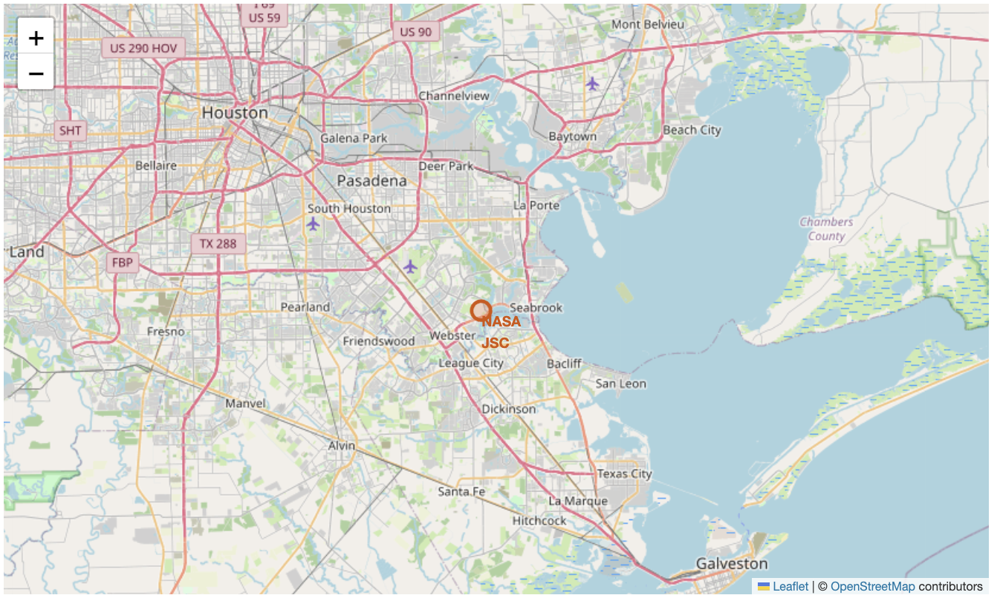

and you should find a small yellow circle near the city of Houston and you can zoom-in to see a larger circle.


Now, let's add a circle for each launch site in data frame `launch_sites`


*TODO:*  Create and add `folium.Circle` and `folium.Marker` for each launch site on the site map


An example of folium.Circle:


`folium.Circle(coordinate, radius=1000, color='#000000', fill=True).add_child(folium.Popup(...))`


An example of folium.Marker:


`folium.map.Marker(coordinate, icon=DivIcon(icon_size=(20,20),icon_anchor=(0,0), html='<div style="font-size: 12; color:#d35400;"><b>%s</b></div>' % 'label', ))`


In [8]:
# Initial the map
site_map = folium.Map(location=nasa_coordinate, zoom_start=5)

# For each launch site, add a Circle object based on its coordinate (Lat, Long) values. In addition, add Launch site name as a popup label
for index, row in launch_sites_df.iterrows():
    
    coordinate = [row['Lat'], row['Long']]

    circle = folium.Circle(location=coordinate, radius=1000, color='#d35400', fill=True).add_child(folium.Popup(row['Launch Site']))
    marker = folium.map.Marker(
        coordinate,
        icon=DivIcon(
            icon_size=(20, 20),
            icon_anchor=(0, 0),                     
            html='<div style="font-size: 12px; color:#d35400;"><b>%s</b></div>' % row['Launch Site'],
        )
    )
    
    site_map.add_child(circle)
    site_map.add_child(marker)

    # 赤道（緯度 0 度）に赤い線を引く
    folium.PolyLine(locations=[[0, -180], [0, 180]], color='red', weight=2, tooltip='Equator').add_to(site_map)

site_map

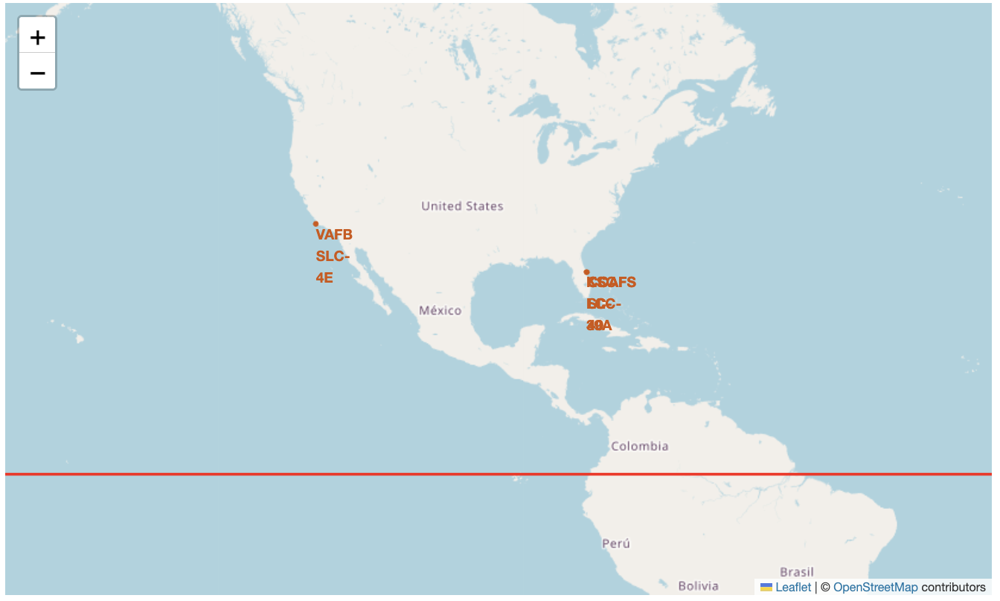

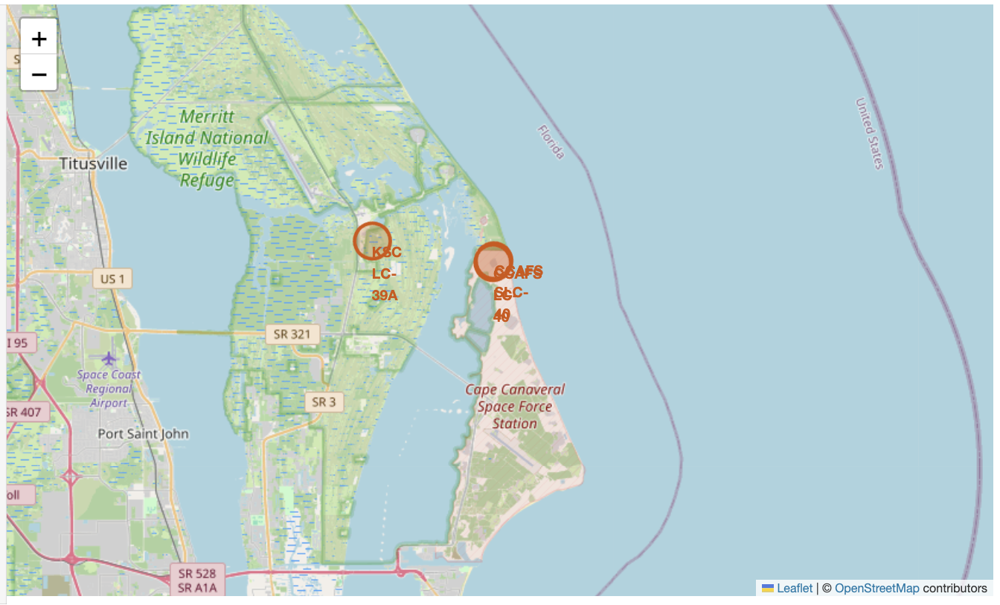

The generated map with marked launch sites should look similar to the following:


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/launch_site_markers.png">
</center>


Now, you can explore the map by zoom-in/out the marked areas
, and try to answer the following questions:

*   Are all launch sites in proximity to the Equator line?
*   Are all launch sites in very close proximity to the coast?

Also please try to explain your findings.


CCAFS LC-40 and CCAFS SLC-40 are at the same location (on the Atlantic coast of Florida), and KSC LC-39A is nearby (also on the Atlantic coast of Florida). Only VAFB SLC-4E is far away from the others (on the Pacific coast of California).
CCAFS LC-40 and CCAFS SLC-40 are at the same location because they are the old and new names of the same launch pad.
All launch sites share two features: they are close to the coast, and they are in the southern part of the U.S. mainland.
Being close to the coast is mainly for safety: rockets are launched over the ocean, so debris or a failed rocket falls into the sea rather than onto populated areas. It also makes it possible to recover the first stage on a drone ship at sea.
Being in the south helps eastward launches from Florida, because sites closer to the equator can make more use of the Earth's rotation. This does not apply to VAFB, which launches southward into polar orbits over the Pacific Ocean.

---

CCAFS LC-40 と CCAFS SLC-40 は同じ場所（フロリダ州・大西洋沿い）にあり、KSC LC-39A はその近く（同じくフロリダ州・大西洋沿い）にある。VAFB SLC-4E だけが離れた場所（カリフォルニア州・太平洋沿い）にある。
CCAFS LC-40 と CCAFS SLC-40 が同じ場所にあるのは、同じ発射台の旧名と新名だからである。
すべての発射場に共通する特徴は、海岸に近いことと、アメリカ本土の南寄りにあることである。
海岸に近い主な理由は安全である。ロケットは海の上に向けて打ち上げられるので、部品や失敗したロケットは人の住む場所ではなく海に落ちる。また、海上のドローン船で第1段を回収することもできる。
南寄りであることは、赤道に近い発射場ほど地球の自転を多く利用できるため、フロリダからの東向きの打ち上げに有利である。ただし、太平洋の上を南向きに打ち上げて極軌道に入れる VAFB には、この理由は当てはまらない。

# Task 2: Mark the success/failed launches for each site on the map

Next, let's try to enhance the map by adding the launch outcomes for each site, and see which sites have high success rates.
Recall that data frame spacex_df has detailed launch records, and the `class` column indicates if this launch was successful or not


In [9]:
spacex_df.tail(10)

,Launch Site,Lat,Long,class
46,KSC LC-39A,28.573255,-80.646895,1
47,KSC LC-39A,28.573255,-80.646895,1
48,KSC LC-39A,28.573255,-80.646895,1
49,CCAFS SLC-40,28.563197,-80.576820,1
50,CCAFS SLC-40,28.563197,-80.576820,1
51,CCAFS SLC-40,28.563197,-80.576820,0
52,CCAFS SLC-40,28.563197,-80.576820,0
53,CCAFS SLC-40,28.563197,-80.576820,0
54,CCAFS SLC-40,28.563197,-80.576820,1
55,CCAFS SLC-40,28.563197,-80.576820,0


Next, let's create markers for all launch records.
If a launch was successful `(class=1)`, then we use a green marker and if a launch was failed, we use a red marker `(class=0)`


Note that a launch only happens in one of the four launch sites, which means many launch records will have the exact same coordinate. Marker clusters can be a good way to simplify a map containing many markers having the same coordinate.


Let's first create a `MarkerCluster` object


In [10]:
marker_cluster = MarkerCluster()

*TODO:* Create a new column in `spacex_df` dataframe called `marker_color` to store the marker colors based on the `class` value


In [11]:
spacex_df['class'].dtype

dtype('int64')

In [12]:
color_map = {1: 'green', 0: 'red',}
spacex_df['marker_color'] = spacex_df['class'].map(color_map)
spacex_df[['class', 'marker_color']].value_counts()

class  marker_color
0      red             32
1      green           24
Name: count, dtype: int64

*TODO:* For each launch result in `spacex_df` data frame, add a `folium.Marker` to `marker_cluster`


In [13]:
site_map.add_child(marker_cluster)

for index, record in spacex_df.iterrows():
    marker = folium.Marker(
        [record['Lat'], record['Long']],
        icon=folium.Icon(color='white', icon_color=record['marker_color']), 
        popup=f"{record['Launch Site']} (class={record['class']})"
    )
    marker_cluster.add_child(marker)

site_map

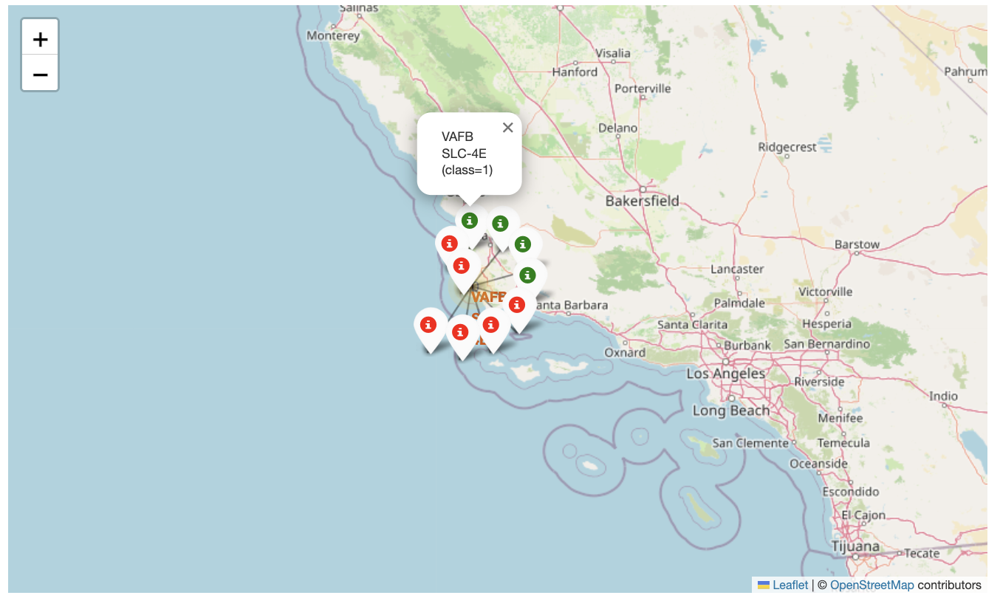

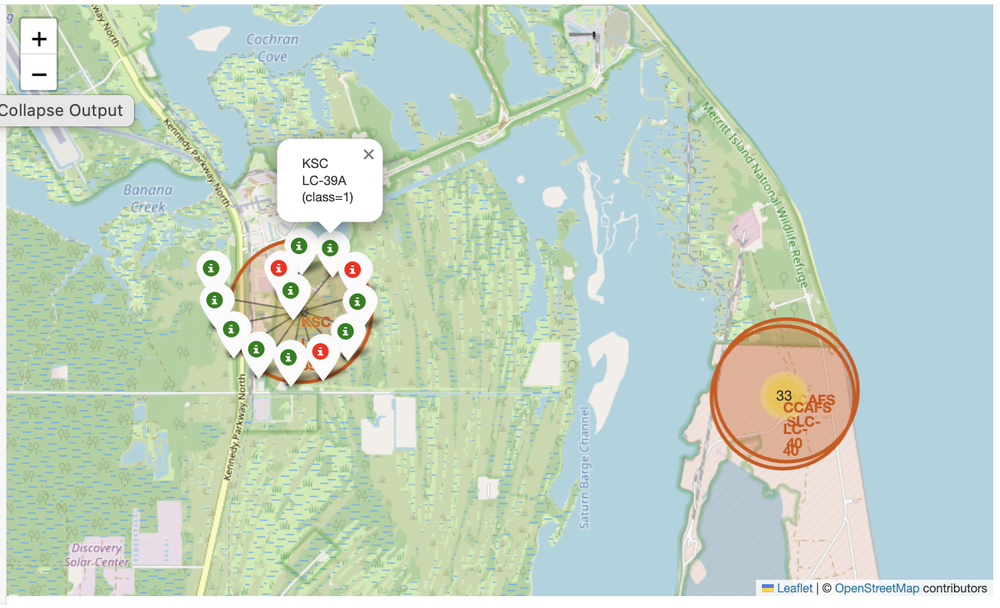

Your updated map may look like the following screenshots:


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/launch_site_marker_cluster.png">
</center>


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/launch_site_marker_cluster_zoomed.png">
</center>


- The red markers also include flights that did not attempt a landing and flights with a controlled ocean landing.
- CRS-7 (2015, exploded during launch) is shown in green because of an error in the data.
- CCAFS LC-40 and CCAFS SLC-40 almost overlap even when zoomed in (about 0.11 km apart).
- The launch sites were used in different periods: CCAFS LC-40 from June 2010 to August 2016, CCAFS SLC-40 from December 2017 to June 2018, KSC LC-39A from February 2017 to May 2018, and VAFB SLC-4E from September 2013 to May 2018. Since early flights often did not attempt a landing, differences in success between sites partly reflect these differences in timing.

---

- 赤には、「着陸を試みていない便」と「海への制御着水」も入っています。
- CRS-7（2015年、打ち上げ中に爆発）は、データの誤りで緑になっています。
- CCAFS LC-40 と SLC-40 は、拡大してもほぼ同じ位置に重なります（約 0.11 km）。
- 発射場ごとに使われた時期が違う。CCAFS LC-40 は2010年6月〜2016年8月、CCAFS SLC-40 は2017年12月〜2018年6月、KSC LC-39A は2017年2月〜2018年5月、VAFB SLC-4E は2013年9月〜2018年5月。初期の便は着陸を試みていないことが多いので、発射場ごとの成功の差には、この時期の違いも一部表れている。

From the color-labeled markers in marker clusters, you should be able to easily identify which launch sites have relatively high success rates.


# TASK 3: Calculate the distances between a launch site to its proximities

Next, we need to explore and analyze the proximities of launch sites.


Let's first add a `MousePosition` on the map to get coordinate for a mouse over a point on the map. As such, while you are exploring the map, you can easily find the coordinates of any points of interests (such as railway)


In [14]:
# Add Mouse Position to get the coordinate (Lat, Long) for a mouse over on the map
formatter = "function(num) {return L.Util.formatNum(num, 5);};"
mouse_position = MousePosition(
    position='topright',
    separator=' Long: ',
    empty_string='NaN',
    lng_first=False,
    num_digits=20,
    prefix='Lat:',
    lat_formatter=formatter,
    lng_formatter=formatter,
)

site_map.add_child(mouse_position)
site_map

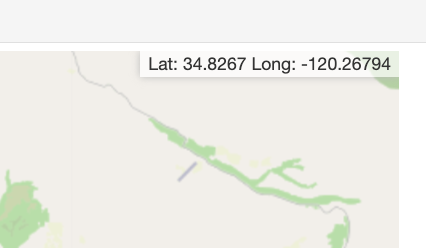

Now zoom in to a launch site and explore its proximity to see if you can easily find any railway, highway, coastline, etc. Move your mouse to these points and mark down their coordinates (shown on the top-left) in order to the distance to the launch site.


In [15]:
from math import sin, cos, sqrt, atan2, radians

def calculate_distance(lat1, lon1, lat2, lon2):
    # approximate radius of earth in km
    R = 6373.0

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    distance = R * c
    return distance

*TODO:* Mark down a point on the closest coastline using MousePosition and calculate the distance between the coastline point and the launch site.


In [16]:
# The closest point on the coastline to VAFB SLC-4E
vafb = launch_sites_df[launch_sites_df['Launch Site'] == 'VAFB SLC-4E'].iloc[0]

launch_site_lat = vafb['Lat']
launch_site_lon = vafb['Long']
coastline_lat = 34.6362
coastline_lon = -120.62496

distance_coastline = calculate_distance(launch_site_lat, launch_site_lon, coastline_lat, coastline_lon)
distance_coastline

1.353699996614433

In [17]:
distance_marker = folium.Marker(
    [coastline_lat, coastline_lon],
    icon=DivIcon(
        icon_size=(150,20),
        icon_anchor=(0,0),
        html='<div style="font-size: 12px; color:#d35400;"><b>%s</b></div>' % f"Coastline: {distance_coastline:.2f} KM",
        )
)
site_map.add_child(distance_marker)

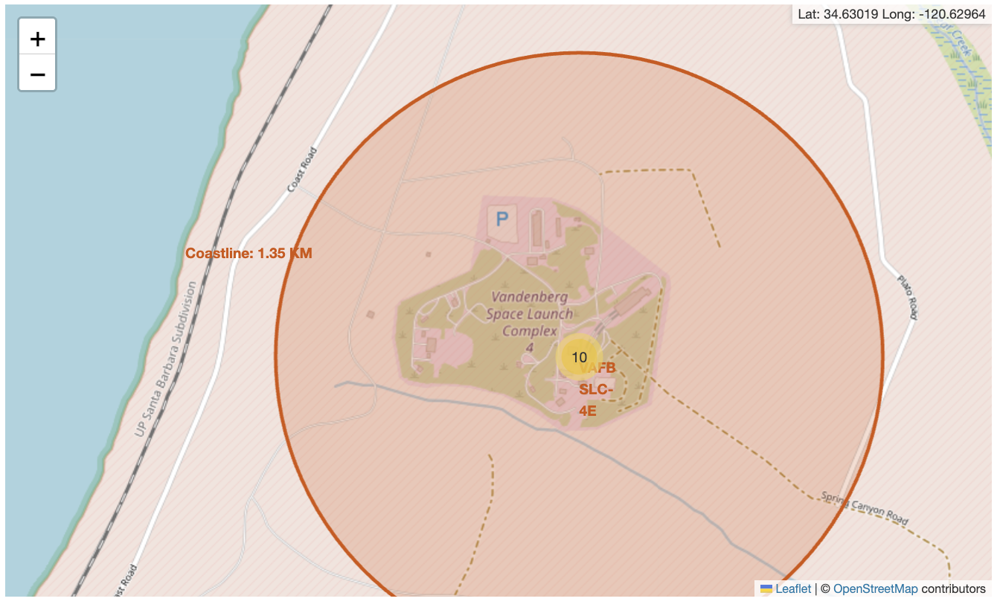

*TODO:* Draw a `PolyLine` between a launch site to the selected coastline point


In [18]:
lines = folium.PolyLine(locations=[[launch_site_lat, launch_site_lon], [coastline_lat, coastline_lon]], weight=1)
site_map.add_child(lines)

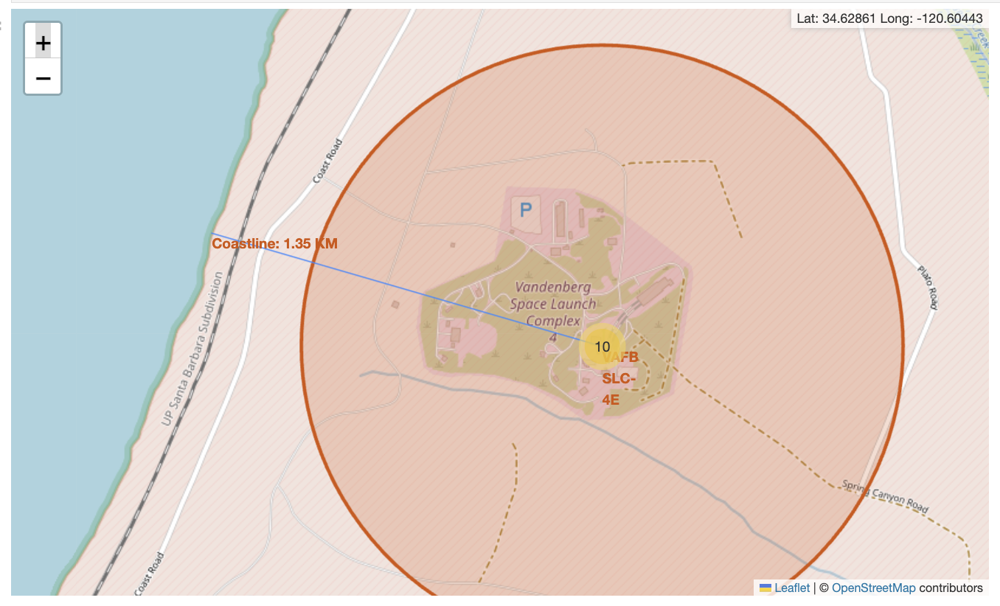

Your updated map with distance line should look like the following screenshot:


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/launch_site_marker_distance.png">
</center>


*TODO:* Similarly, you can draw a line betwee a launch site to its closest city, railway, highway, etc. You need to use `MousePosition` to find the their coordinates on the map first


A railway map symbol may look like this:


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/railway.png">
</center>


A highway map symbol may look like this:


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/highway.png">
</center>


A city map symbol may look like this:


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_3/images/city.png">
</center>


In [19]:
# ===== The closest points (coastline, railway, highway, city) to VAFB SLC-4E =====
points = { 
    'Railway':   (34.63596, -120.62394),   # UP Santa Barbara Subdivision
    'Highway':   (34.70368, -120.47546),   # Cabrillo Highway
    'City':      (34.64042, -120.45813),   # Lompoc
}

# ===== For each point: calculate the distance, add a distance label and a line from the launch site =====
for name, (lat, lon) in points.items():
    distance = calculate_distance(launch_site_lat, launch_site_lon, lat, lon)

    distance_marker = folium.Marker(
        [lat, lon],
        icon=DivIcon(
            icon_size=(150,20),
            icon_anchor=(0,0),
            html='<div style="font-size: 12px; color:#d35400;"><b>%s</b></div>' % f"{name}: {distance:.2f} KM",
        )
    )
    site_map.add_child(distance_marker)

    lines = folium.PolyLine(locations=[[launch_site_lat, launch_site_lon], [lat, lon]], weight=1)
    site_map.add_child(lines)

site_map

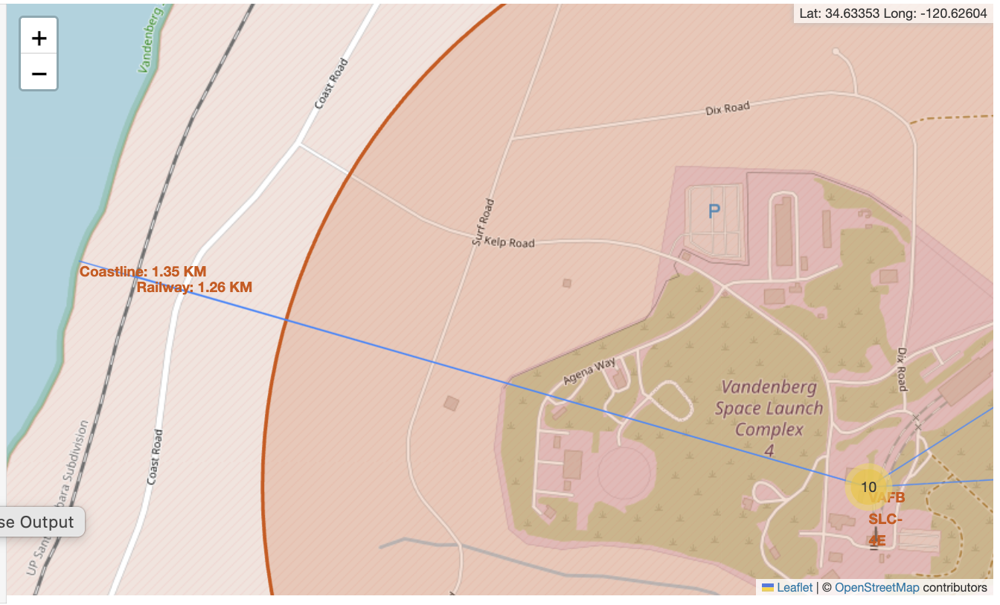

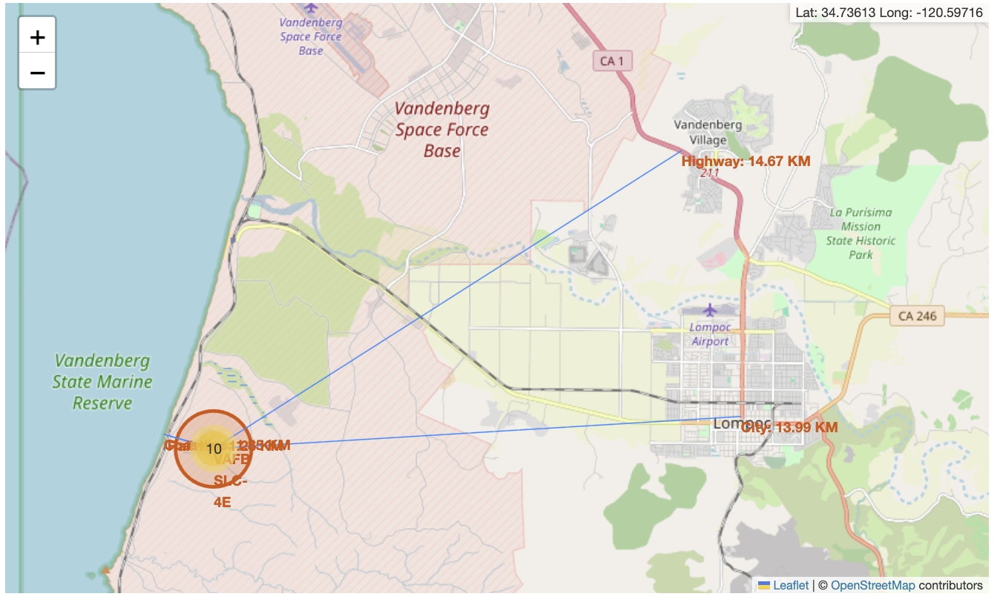

After you plot distance lines to the proximities, you can answer the following questions easily:

*   Are launch sites in close proximity to railways?
*   Are launch sites in close proximity to highways?
*   Are launch sites in close proximity to coastline?
*   Do launch sites keep certain distance away from cities?

Also please try to explain your findings.


Distances from VAFB SLC-4E (straight-line distances calculated from the coordinates in this dataset):

| Point | Distance |
| --- | --- |
| Coastline | about 1.35 km |
| Railway (UP Santa Barbara Subdivision) | about 1.26 km |
| City (Lompoc) | about 13.99 km |
| Highway (Cabrillo Highway) | about 14.67 km |

- Are launch sites in close proximity to railways? Yes. The railway is only about 1 km away, which helps transport rockets and heavy equipment.
- Are launch sites in close proximity to highways? Not very close. The nearest highway is about 15 km away.
- Are launch sites in close proximity to coastline? Yes. The coastline is about 1 km away, so rockets can be launched over the ocean.
- Do launch sites keep certain distance away from cities? Yes. The nearest city (Lompoc) is about 14 km away, which reduces the risk to people in case of an accident.

Note: These results are based only on VAFB SLC-4E.

---

VAFB SLC-4E からの距離（このデータの座標から計算した直線距離）：

| 点 | 距離 |
| --- | --- |
| 海岸線 | 約 1.35 km |
| 鉄道（UP Santa Barbara Subdivision） | 約 1.26 km |
| 都市（Lompoc） | 約 13.99 km |
| 高速道路（Cabrillo Highway） | 約 14.67 km |

- 発射場は鉄道の近くにあるか？ → はい。鉄道までは約1 km で、ロケットや重い機材を運ぶのに役立つ。
- 発射場は高速道路の近くにあるか？ → あまり近くない。最も近い高速道路まで約15 km ある。
- 発射場は海岸線の近くにあるか？ → はい。海岸線まで約1 km で、ロケットを海の上に向けて打ち上げられる。
- 発射場は都市から一定の距離を保っているか？ → はい。最も近い都市（Lompoc）まで約14 km あり、事故が起きたときの人への危険を減らしている。

注：この結果は VAFB SLC-4E の1か所だけにもとづく。

# Next Steps:

Now you have discovered many interesting insights related to the launch sites' location using folium, in a very interactive way. Next, you will need to build a dashboard using Ploty Dash on detailed launch records.


## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log--!>


<!--| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|--!>


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
